<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/week6/lesson21/Lesson21_Teaching_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MAMBA: Mathematical Sciences for Brain Data**
## Lesson 21 — ODEs and the Passive Membrane: Equilibria, Time Constants and the Euler Method

**Course:** MAMBA: Mathematical Sciences for Brain Data\
**Week:** Week 6 — Differential Equations\
**Lesson:** Lesson 21\
**Notebook type:** Teaching notebook

> *"A differential equation does not tell you where the system is. It tells you where it is going next."*

---

### From snapshots to dynamics

Lessons 16–20 described neural data statistically: distributions, likelihoods, intervals. This lesson starts the last block of the course, on **dynamics**: rules that say how a quantity changes from moment to moment. Such a rule is a **differential equation**, and the simplest useful one in neuroscience describes the membrane potential of a neuron that has no spiking machinery, the **passive membrane**:

$$\tau_m \frac{dV}{dt} = -(V - E_L) + R_m I(t).$$

We will see:
1. the derivative as the **rate of change of a state**, and **first-order ODEs**, autonomous and non-autonomous;
2. **initial-value problems**, **equilibria**, **time constants** and the **exponential approach** to equilibrium;
3. the **membrane equation**, where it comes from, its units, and how a membrane filters its input;
4. the **Euler method**: step size, local and global error, instability, and comparison with a **reference solver**;
5. a mini-lab that fits the membrane equation to a **real neuron** and checks where it fails.

The mini-lab uses whole-cell current-clamp recordings distributed with the open-source [pyABF](https://github.com/swharden/pyABF) package (MIT licence). Lesson 22 adds a threshold and a reset to the same equation to make the leaky integrate-and-fire neuron; Lesson 23 couples two such equations.

### Import Dependencies

In [1]:
# SETUP CELL
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from scipy.integrate import solve_ivp
from scipy.optimize import curve_fit

RNG = np.random.default_rng(42)

# The same colourblind-conscious palette and markers as Lessons 1-20.
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
MARKERS = ['o', 's', '^', 'D', 'v', 'P']
LINESTYLES = ['-', '--', ':', '-.']

print("Setup complete.")

Setup complete.


### Interactive and animated plotting tools

As before, each static figure is followed by a **Plotly version** that you can zoom, pan, hover over, and save. Sliders are pre-computed frames, so they work offline and in a static viewer.

In [2]:
# INTERACTIVE/ANIMATION SETUP
import sys
import plotly.io as pio

if 'google.colab' not in sys.modules:
    pio.renderers.default = 'notebook_connected'
pio.templates['plotly_white'].layout.xaxis.showgrid = False
pio.templates['plotly_white'].layout.yaxis.showgrid = False

PLOTLY_CONFIG = {'displaylogo': False, 'responsive': True, 'scrollZoom': True,
                 'toImageButtonOptions': {'format': 'png', 'scale': 2}}

def play_pause_and_slider(labels, prefix, duration=150):
    # Play/Pause buttons and a frame slider, as used in Lessons 1-20.
    buttons = [dict(
        type='buttons', showactive=False, x=0.0, y=-0.12, xanchor='left', yanchor='top',
        buttons=[
            dict(label='Play', method='animate', args=[None, {'frame': {'duration': duration, 'redraw': True}, 'transition': {'duration': 0}, 'fromcurrent': True}]),
            dict(label='Pause', method='animate', args=[[None], {'frame': {'duration': 0, 'redraw': False}, 'mode': 'immediate'}]),
        ],
    )]
    sliders = [dict(
        active=0, currentvalue={'prefix': prefix}, pad={'t': 50},
        steps=[dict(label=str(lab), method='animate', args=[[str(k)], {'mode': 'immediate', 'frame': {'duration': 0, 'redraw': True}, 'transition': {'duration': 0}}])
               for k, lab in enumerate(labels)],
    )]
    return buttons, sliders

print('Interactive plotting and animation tools are ready.')

Interactive plotting and animation tools are ready.


# **Motivation and Retrieval: What Does Current Do to a Neuron?**

An electrode injects a constant current $I = 100$ pA into a neuron. The cell membrane is a thin insulating layer separating charged solutions: a **capacitor**, here with capacitance $C = 100$ pF. Charge accumulates on it, and the voltage across it is charge divided by capacitance.

- **Lesson 13 (accumulation):** charge is the integral of current, $Q(t) = \int_0^t I\,dt' = I t$, so a perfect capacitor would charge at a constant rate, $dV/dt = I/C$.
- With the units: $I/C = 100\ \text{pA} / 100\ \text{pF} = 1\ \text{V/s} = 1$ mV/ms.

**Prediction before running:** after 50 ms of current, how far has the membrane potential moved? 50 mV?

Real neurons move about 20 mV and then **stop**: the voltage levels off. The membrane is not a perfect capacitor; it also **leaks** current through ion channels that are open at rest, and the leak grows as the voltage moves away from rest. The balance between injected current and leak is a **differential equation**, and its solution is the subject of this lesson.

tau_m = R_m C_m = 20 ms;  R_m I = 20 mV
after 50 ms: perfect capacitor moved 50.0 mV, leaky membrane 18.4 mV


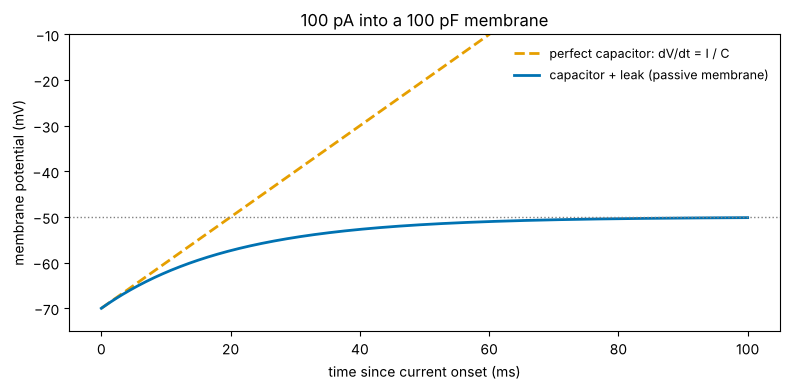

In [3]:
C_m, I_inj = 100e-12, 100e-12                                              # capacitance (F), injected current (A)
R_m, E_L = 200e6, -70e-3                                                   # membrane resistance (ohm), resting (leak reversal) potential (V)
tau_m = R_m * C_m                                                          # membrane time constant (s)
t = np.linspace(0, 0.1, 1001)                                              # (1001,) time, s
V_cap = E_L + I_inj / C_m * t                                              # perfect capacitor: linear charging
V_leaky = E_L + R_m * I_inj * (1 - np.exp(-t / tau_m))                     # capacitor + leak (derived in Part 2)
print(f"tau_m = R_m C_m = {tau_m * 1e3:.0f} ms;  R_m I = {R_m * I_inj * 1e3:.0f} mV")
print(f"after 50 ms: perfect capacitor moved {(V_cap[500] - E_L) * 1e3:.1f} mV, leaky membrane {(V_leaky[500] - E_L) * 1e3:.1f} mV")
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(t * 1e3, V_cap * 1e3, '--', color=PALETTE[4], lw=2, label='perfect capacitor: dV/dt = I / C')
ax.plot(t * 1e3, V_leaky * 1e3, color=PALETTE[0], lw=2, label='capacitor + leak (passive membrane)')
ax.axhline((E_L + R_m * I_inj) * 1e3, color='grey', ls=':', lw=1)
ax.set_ylim(-75, -10); ax.set_xlabel('time since current onset (ms)'); ax.set_ylabel('membrane potential (mV)')
ax.set_title('100 pA into a 100 pF membrane'); ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

# **Part 1: The Derivative as a Rate of Change of State**

A **state variable** is a quantity that summarises the system at an instant: a membrane potential $V$ (mV), an intracellular calcium concentration (µM), a synaptic conductance (nS), a population firing rate (spikes/s), a network weight. Lesson 9 defined $dV/dt$ as the limit of $\Delta V/\Delta t$: how fast the state changes.

An **ordinary differential equation** (ODE) of first order specifies that rate as a function of the current state and possibly of time:

$$\frac{dx}{dt} = f(x, t).$$

- **First order:** only the first derivative appears.
- **Autonomous:** $f$ depends on $x$ only, $dx/dt = f(x)$. The rule is the same at every moment (a membrane with constant input).
- **Non-autonomous:** $f$ depends explicitly on $t$, typically through an input, $dx/dt = f(x, I(t))$ (a membrane driven by a time-varying current).

**Reading an ODE geometrically.** At every point $(t, x)$ the equation gives a slope. Drawing those slopes as short line segments gives a **direction field**; a solution is a curve that is tangent to the field everywhere. You can sketch solutions before solving anything.

Examples in neuroscience, all of the form $\tau\,dx/dt = -(x - x_\infty)$ plus input:
- calcium concentration after a spike decays back to baseline (time constant tens to hundreds of ms);
- a synaptic conductance decays after a presynaptic spike (a few ms for AMPA receptors);
- spike-frequency adaptation builds up and decays (hundreds of ms);
- a firing-rate unit relaxes towards its input-driven value (Lesson 23).

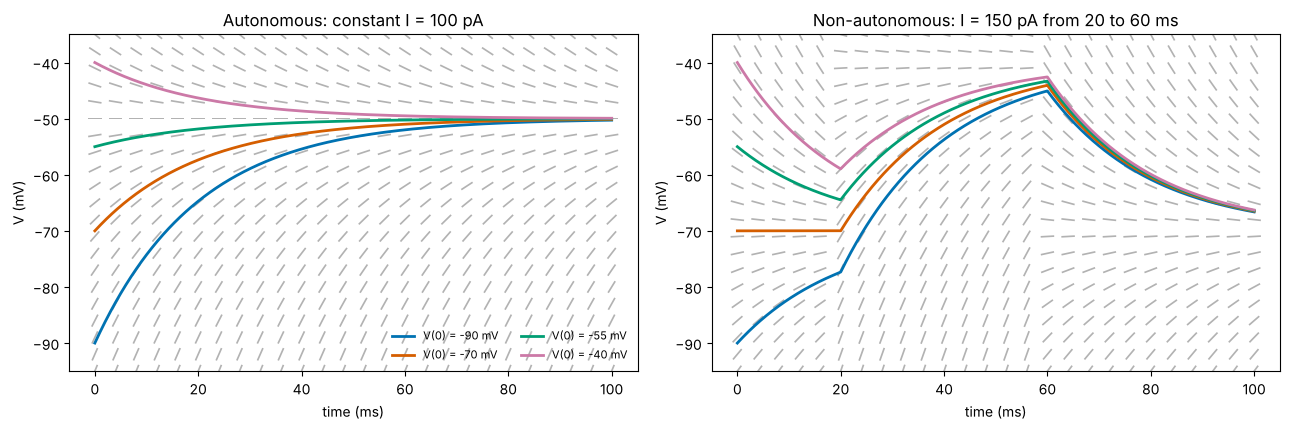

In [4]:
tau, E_L, R = 20.0, -70.0, 0.2                                             # ms, mV, mV/pA (0.2 mV/pA = 200 megaohm)
def f_membrane(V, I):
    # dV/dt (mV/ms) of the passive membrane for voltage V (mV) and injected current I (pA).
    return (-(V - E_L) + R * I) / tau

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
tt = np.linspace(0, 100, 26); VV = np.linspace(-95, -35, 21)
Tg, Vg = np.meshgrid(tt, VV)                                               # (21, 26) grid of (time ms, voltage mV)
for ax, I_of_t, title in [(axes[0], lambda t: 100.0 + 0 * t, 'Autonomous: constant I = 100 pA'),
                          (axes[1], lambda t: np.where((t >= 20) & (t < 60), 150.0, 0.0), 'Non-autonomous: I = 150 pA from 20 to 60 ms')]:
    S = f_membrane(Vg, I_of_t(Tg))                                         # slopes, mV/ms
    L = np.sqrt(1 + S**2)
    ax.quiver(Tg, Vg, 1 / L, S / L, angles='xy', color='grey', alpha=0.6, width=0.003, headwidth=0, headlength=0, headaxislength=0, pivot='mid')
    for k, V0 in enumerate([-90, -70, -55, -40]):
        sol = solve_ivp(lambda t, V: f_membrane(V, I_of_t(t)), [0, 100], [V0], max_step=0.1)
        ax.plot(sol.t, sol.y[0], color=PALETTE[k], lw=2, label=f'V(0) = {V0} mV')
    ax.set_xlabel('time (ms)'); ax.set_ylabel('V (mV)'); ax.set_title(title); ax.set_ylim(-95, -35)
axes[0].legend(fontsize=8, frameon=False, loc='lower right', ncol=2)
plt.tight_layout(); plt.show()

- **Left (autonomous).** The field is the same at every time. All solutions, whatever their starting value, are drawn to the same level, $E_L + RI = -70 + 0.2 \times 100 = -50$ mV, where the slope is zero. Curves never cross: from any point there is exactly one way forward.
- **Right (non-autonomous).** The field changes when the current switches on at 20 ms and off at 60 ms. The target level jumps from $-70$ mV to $-40$ mV and back, and the solutions chase it, lagging behind.

The slope is steepest far from the target and vanishes at it. That single feature, **the rate of change is proportional to the distance from equilibrium**, explains everything in Part 2.

# **Part 2: Initial-Value Problems, Equilibria and Time Constants**

An ODE alone has infinitely many solutions (one per curve in the direction field). An **initial-value problem** (IVP) adds a starting state, $x(t_0) = x_0$, and then (for well-behaved $f$) has exactly one solution.

**Equilibria.** A state $x^*$ with $f(x^*) = 0$ does not change: if the system starts there, it stays there. It is **stable** if nearby states move towards it and **unstable** if they move away. In one dimension the sign of $f$ on each side decides: stable if $f'(x^*) < 0$ (Lesson 6's continuous-time condition, eigenvalue negative).

**The linear relaxation equation.** Consider

$$\tau \frac{dx}{dt} = -(x - x_\infty), \qquad x(0) = x_0,$$

with constants $\tau > 0$ and $x_\infty$. Its only equilibrium is $x_\infty$, and $f'(x) = -1/\tau < 0$, so it is stable. The solution is

$$x(t) = x_\infty + (x_0 - x_\infty)\,e^{-t/\tau}.$$

*Check:* $dx/dt = -(x_0 - x_\infty)e^{-t/\tau}/\tau = -(x - x_\infty)/\tau$, and $x(0) = x_0$. ✓ (Derivation: write $y = x - x_\infty$; then $dy/dt = -y/\tau$, whose solution is the exponential of Lesson 8.)

**The time constant $\tau$.** The distance from equilibrium shrinks by a factor $e$ every $\tau$:
- after $\tau$: 37% of the initial distance remains (the response has covered 63%);
- after $3\tau$: 5% remains; after $5\tau$: under 1%;
- the **half-life** is $\tau \ln 2 \approx 0.69\,\tau$.

The approach is fastest at the start and never quite finishes: equilibrium is reached only asymptotically.

In [5]:
tau, x0, x_inf = 20.0, -70.0, -50.0                                        # ms, mV, mV
t = np.linspace(0, 120, 12001)                                             # (12001,) ms
x = x_inf + (x0 - x_inf) * np.exp(-t / tau)                                # (12001,) mV
# Check the ODE numerically: the finite-difference derivative (Lesson 9) against -(x - x_inf)/tau.
dxdt = np.gradient(x, t)
print(f"max |dx/dt - (-(x - x_inf)/tau)| = {np.max(np.abs(dxdt - (-(x - x_inf) / tau))):.1e} mV/ms (finite-difference error only)")
for k in [1, 2, 3, 5]:
    i = np.argmin(np.abs(t - k * tau))
    print(f"t = {k} tau = {k * tau:>5.0f} ms: fraction of the distance remaining {(x[i] - x_inf) / (x0 - x_inf):.3f}  (e^-{k} = {np.exp(-k):.3f})")
print(f"half-life tau ln 2 = {tau * np.log(2):.1f} ms")

max |dx/dt - (-(x - x_inf)/tau)| = 2.5e-04 mV/ms (finite-difference error only)
t = 1 tau =    20 ms: fraction of the distance remaining 0.368  (e^-1 = 0.368)
t = 2 tau =    40 ms: fraction of the distance remaining 0.135  (e^-2 = 0.135)
t = 3 tau =    60 ms: fraction of the distance remaining 0.050  (e^-3 = 0.050)
t = 5 tau =   100 ms: fraction of the distance remaining 0.007  (e^-5 = 0.007)
half-life tau ln 2 = 13.9 ms


**Nonlinear one-dimensional ODEs** can have several equilibria. A firing-rate unit with recurrent self-excitation (a population exciting itself, Lesson 23) obeys

$$\tau \frac{dr}{dt} = -r + F(w r + I), \qquad F(u) = \frac{1}{1 + e^{-(u - \theta)/k}},$$

with rate $r$ as a fraction of the maximum. Its equilibria solve $r = F(wr + I)$: where the line $r$ meets the sigmoid. The **phase line** plots $dr/dt$ against $r$: where it is positive $r$ increases (arrow right), where negative $r$ decreases. Equilibria where $dr/dt$ crosses zero **downwards** are stable; crossing **upwards**, unstable.

weak recurrence (w = 0.3, I = 0.35): one equilibrium: equilibrium r* = 0.500 (stable)
strong recurrence (w = 1, I = 0): bistable: equilibrium r* = 0.002 (stable)
strong recurrence (w = 1, I = 0): bistable: equilibrium r* = 0.500 (unstable)
strong recurrence (w = 1, I = 0): bistable: equilibrium r* = 0.998 (stable)


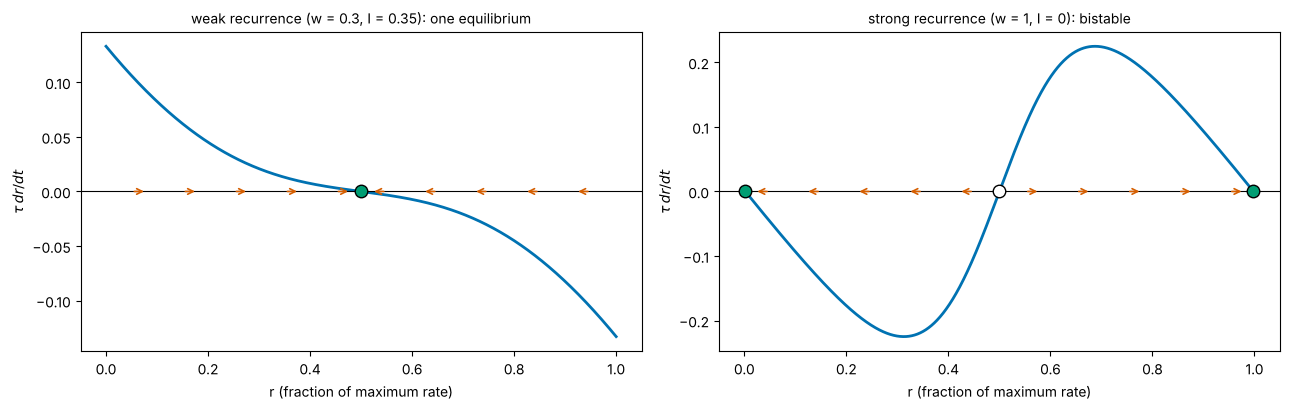

In [6]:
def F(u, theta=0.5, k=0.08):
    return 1 / (1 + np.exp(-(u - theta) / k))
r = np.linspace(0, 1, 2000)                                                 # (2000,) rate, fraction of maximum (grid avoids landing exactly on r = 0.5)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (w, I, lab) in zip(axes, [(0.3, 0.35, 'weak recurrence (w = 0.3, I = 0.35): one equilibrium'), (1.0, 0.0, 'strong recurrence (w = 1, I = 0): bistable')]):
    g = -r + F(w * r + I)                                                  # tau dr/dt (fraction of max), tau = 1
    ax.plot(r, g, color=PALETTE[0], lw=2); ax.axhline(0, color='black', lw=0.8)
    zc = np.where(np.diff(np.sign(g)) != 0)[0]
    for i in zc:
        stable = g[i] > g[i + 1]
        ax.plot(r[i], 0, 'o', ms=9, color=PALETTE[2] if stable else 'white', markeredgecolor='black', zorder=3)
        print(f"{lab}: equilibrium r* = {r[i]:.3f} ({'stable' if stable else 'unstable'})")
    for xa in np.linspace(0.05, 0.95, 10):
        gi = np.interp(xa, r, g)
        ax.annotate('', xy=(xa + 0.03 * np.sign(gi), 0.0), xytext=(xa, 0.0), arrowprops=dict(arrowstyle='->', color=PALETTE[1], lw=1.2))
    ax.set_xlabel('r (fraction of maximum rate)'); ax.set_ylabel(r'$\tau\,dr/dt$'); ax.set_title(lab, fontsize=10)
plt.tight_layout(); plt.show()

With weak recurrence there is one stable rate. With strong recurrence there are two stable equilibria (a low "off" state and a high "on" state) separated by an unstable one: the unit **remembers** which state it was put in. This is the simplest model of persistent activity in working memory, and the reason the initial condition matters in a nonlinear IVP. Lesson 23 extends phase lines to phase planes.

# **Part 3: The Membrane Equation**

**From circuit to equation.** Model a patch of membrane as a capacitor $C_m$ in parallel with a resistor $R_m$ (the open leak channels) in series with a battery $E_L$ (the leak reversal potential, set by ion concentration gradients). By conservation of charge (Kirchhoff's current law), the injected current is split between charging the capacitor and leaking out:

$$I(t) = \underbrace{C_m \frac{dV}{dt}}_{\text{capacitive}} + \underbrace{\frac{V - E_L}{R_m}}_{\text{leak (Ohm's law)}}.$$

Multiplying by $R_m$ and writing $\tau_m = R_m C_m$ gives the **membrane equation**

$$\tau_m \frac{dV}{dt} = -(V - E_L) + R_m I(t).$$

This is the relaxation equation of Part 2 with $V_\infty = E_L + R_m I$: for a constant current the voltage relaxes exponentially, with time constant $\tau_m$, to a level shifted from rest by $R_m I$ (Ohm's law at steady state).

**Units (check them every time).**

| Quantity | Typical value | Unit arithmetic |
|---|---|---|
| $C_m$ | 50–200 pF for a whole neuron (about 1 µF/cm² of membrane) | |
| $R_m$ | 50–500 MΩ (input resistance) | |
| $\tau_m = R_m C_m$ | 10–30 ms | 1 MΩ × 1 pF = $10^6 \times 10^{-12}$ s = 1 µs, so 200 MΩ × 100 pF = 20,000 µs = 20 ms |
| $R_m I$ | a few to tens of mV | 1 MΩ × 1 pA = 1 µV, so 200 MΩ × 100 pA = 20 mV |

**Superposition.** The equation is **linear** in $V - E_L$ and $I$: the response to a sum of inputs is the sum of the responses, and doubling the current doubles the deflection. The mini-lab tests this on a real neuron.

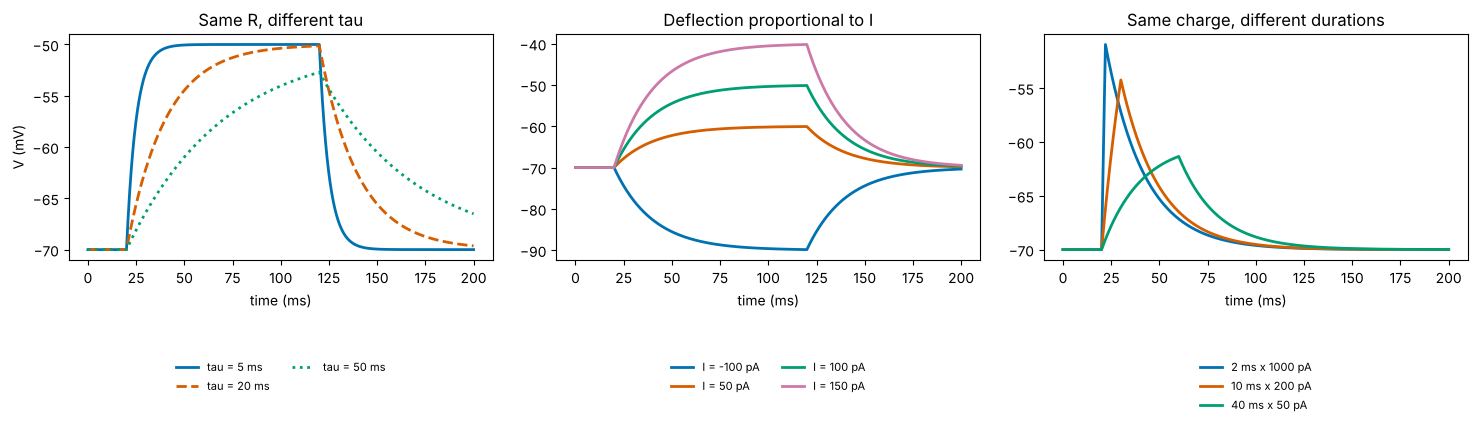

pulse  2 ms x  1000 pA: peak deflection 19.03 mV  (charge Q / C = 20 mV if no leak)
pulse 10 ms x   200 pA: peak deflection 15.74 mV  (charge Q / C = 20 mV if no leak)
pulse 40 ms x    50 pA: peak deflection 8.65 mV  (charge Q / C = 20 mV if no leak)


In [7]:
def membrane_exact_step(t, I_amp, t_on, t_off, tau=20.0, R=0.2, E_L=-70.0):
    # Exact solution for a rectangular current pulse (pA) from t_on to t_off (ms), starting at rest.
    V = np.full_like(t, E_L, dtype=float)
    on = (t >= t_on) & (t < t_off)
    V[on] = E_L + R * I_amp * (1 - np.exp(-(t[on] - t_on) / tau))
    V_end = E_L + R * I_amp * (1 - np.exp(-(t_off - t_on) / tau))
    after = t >= t_off
    V[after] = E_L + (V_end - E_L) * np.exp(-(t[after] - t_off) / tau)
    return V

t = np.linspace(0, 200, 2001)                                               # (2001,) ms
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for k, tau_k in enumerate([5, 20, 50]):
    axes[0].plot(t, membrane_exact_step(t, 100, 20, 120, tau=tau_k), color=PALETTE[k], lw=2, ls=LINESTYLES[k], label=f'tau = {tau_k} ms')
axes[0].set_title('Same R, different tau'); axes[0].set_xlabel('time (ms)'); axes[0].set_ylabel('V (mV)'); axes[0].legend(fontsize=8, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.4), ncol=2)
for k, I_k in enumerate([-100, 50, 100, 150]):
    axes[1].plot(t, membrane_exact_step(t, I_k, 20, 120), color=PALETTE[k], lw=2, label=f'I = {I_k} pA')
axes[1].set_title('Deflection proportional to I'); axes[1].set_xlabel('time (ms)'); axes[1].legend(fontsize=8, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.4), ncol=2)
# Brief pulses: the membrane integrates (low-pass filters) its input.
for k, dur in enumerate([2, 10, 40]):
    amp = 100 * 20 / dur                                                    # same total charge (2 pC) in each pulse
    axes[2].plot(t, membrane_exact_step(t, amp, 20, 20 + dur), color=PALETTE[k], lw=2, label=f'{dur} ms x {amp:.0f} pA')
axes[2].set_title('Same charge, different durations'); axes[2].set_xlabel('time (ms)'); axes[2].legend(fontsize=8, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.4), ncol=1)
plt.tight_layout(); plt.show()
for dur in [2, 10, 40]:
    amp = 100 * 20 / dur
    print(f"pulse {dur:>2} ms x {amp:>5.0f} pA: peak deflection {membrane_exact_step(t, amp, 20, 20 + dur).max() + 70:.2f} mV  (charge Q / C = {amp * dur * 1e-3 / 0.1 * 1e-3 * 1e3:.0f} mV if no leak)")

- **Left.** The time constant sets how fast the membrane follows; the steady level $E_L + R_m I$ does not depend on $\tau$.
- **Middle.** Deflections scale with the current, in both directions: linearity.
- **Right.** For a pulse much shorter than $\tau_m$, the membrane barely leaks during it, so the peak depends on the **charge** delivered ($Q/C$, about 20 mV here), not on the pulse shape: a fast pulse is integrated. For a pulse much longer than $\tau_m$, the peak is set by the current ($R_m I$), not the charge. This is why $\tau_m$ is called the **integration window** of a neuron: inputs arriving within about $\tau_m$ of each other add up.

**Frequency view.** For a sinusoidal current at frequency $f$, the steady response is a sinusoid with amplitude reduced by $1/\sqrt{1 + (2\pi f \tau_m)^2}$: the membrane is a **low-pass filter** with cutoff frequency $1/(2\pi\tau_m)$, about 8 Hz for $\tau_m = 20$ ms.

#### Interactive version: changing the time constant
The slider changes $\tau_m$ (with $R_m$ fixed), for a 100 pA step and a train of brief inputs.

In [8]:
tau_list = [2, 5, 10, 20, 40, 80]
t_i = np.linspace(0, 250, 2501)                                            # (2501,) ms
I_train = np.zeros_like(t_i)
for s in [130, 140, 150, 160, 170]:                                         # five 1 ms pulses, 10 ms apart
    I_train[(t_i >= s) & (t_i < s + 1)] = 1000.0
I_total = np.where((t_i >= 20) & (t_i < 100), 100.0, 0.0) + I_train         # (2501,) pA
def simulate_exact_pw(t, I, tau, R=0.2, E_L=-70.0):
    # Exact update for piecewise-constant input on the grid t (ms).
    V = np.empty_like(t); V[0] = E_L
    for n in range(len(t) - 1):
        dt = t[n + 1] - t[n]; Vinf = E_L + R * I[n]
        V[n + 1] = Vinf + (V[n] - Vinf) * np.exp(-dt / tau)
    return V
fig_t = go.Figure([go.Scatter(x=t_i, y=np.round(simulate_exact_pw(t_i, I_total, tau_list[0]), 3), mode='lines', line=dict(color=PALETTE[0], width=2), name='V'),
                   go.Scatter(x=t_i, y=-75 + I_total / 200, mode='lines', line=dict(color='grey', width=1), name='input (scaled)')])
frames = [go.Frame(name=str(i), traces=[0], data=[go.Scatter(y=np.round(simulate_exact_pw(t_i, I_total, tk), 3))],
                   layout=go.Layout(title=f'tau_m = {tk} ms: step response reaches 63% after {tk} ms; brief inputs {"add up" if tk >= 10 else "barely add up"}'))
          for i, tk in enumerate(tau_list)]
fig_t.frames = frames
buttons, sliders = play_pause_and_slider(tau_list, prefix='tau_m (ms) = ', duration=700)
fig_t.update_layout(title=frames[0].layout.title.text, xaxis=dict(title='time (ms)'), yaxis=dict(title='V (mV)', range=[-76, -35]),
                    template='plotly_white', width=850, height=480, updatemenus=buttons, sliders=sliders)
fig_t.show(config=PLOTLY_CONFIG)

# **Part 4: The Euler Method and Numerical Error**

Most ODEs, including the membrane equation with an arbitrary measured current, have no formula solution. We **step** them forward in time. The derivative is the limit of a difference quotient (Lesson 9), so for a small step $\Delta t$,

$$\frac{x(t + \Delta t) - x(t)}{\Delta t} \approx f(x(t), t) \quad\Longrightarrow\quad x_{n+1} = x_n + \Delta t\, f(x_n, t_n).$$

This is the **(forward) Euler method**: follow the direction field in a straight line for one step, then re-read the slope. For the membrane equation:

$$V_{n+1} = V_n + \frac{\Delta t}{\tau_m}\big(-(V_n - E_L) + R_m I_n\big).$$

**Errors.**
- **Local error** (one step): the Taylor expansion $x(t + \Delta t) = x + \Delta t\,x' + \tfrac12\Delta t^2 x'' + \dots$ shows that Euler drops the $\Delta t^2$ term: the error per step is $O(\Delta t^2)$.
- **Global error** (at a fixed time $T$): about $T/\Delta t$ steps, each adding $O(\Delta t^2)$, so $O(\Delta t)$: halving the step halves the error. Euler is a **first-order method**.
- **Stability.** For $dx/dt = -x/\tau$, Euler gives $x_{n+1} = (1 - \Delta t/\tau)\,x_n$. If $\Delta t > \tau$, the factor is negative and the numerical solution oscillates; if $\Delta t > 2\tau$, its magnitude exceeds 1 and the solution explodes, although the true solution decays (Lesson 6's discrete-time condition, $|\lambda| < 1$).

**Reference solvers.** Library solvers such as `scipy.integrate.solve_ivp` use higher-order methods (by default the Runge–Kutta method RK45, error $O(\Delta t^5)$ per step) and **adapt** the step size to keep the estimated error below a tolerance. We use one as the "truth" when there is no exact solution.

 dt (ms)  steps  max |error| (mV)  error / dt
       8     12            1.7866      0.2233
       4     25            0.8040      0.2010
       2     50            0.3840      0.1920
       1    100            0.1879      0.1879
     0.5    200            0.0929      0.1859
    0.25    400            0.0462      0.1849
   0.125    800            0.0231      0.1844
  0.0625   1600            0.0115      0.1842
log-log slope of error against dt: 1.03  (first-order method: 1)
solve_ivp (RK45, rtol 1e-6): 92 evaluations of f, max |error| 1.8e-05 mV
Euler would need dt = 9.8e-05 ms, about 1,020,188 steps, for the same error


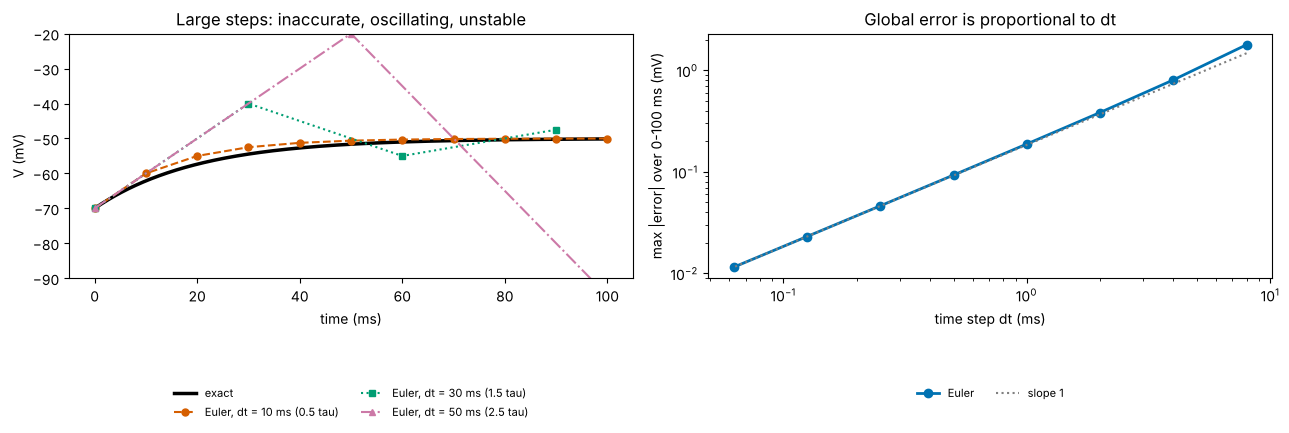

In [9]:
def euler(f, x0, t):
    # Forward Euler on the time grid t: x[n+1] = x[n] + dt * f(x[n], t[n]).
    x = np.empty(len(t)); x[0] = x0
    for n in range(len(t) - 1):
        x[n + 1] = x[n] + (t[n + 1] - t[n]) * f(x[n], t[n])
    return x

tau, E_L, R, I_amp, T_end = 20.0, -70.0, 0.2, 100.0, 100.0                  # ms, mV, mV/pA, pA, ms
f_step = lambda V, t: (-(V - E_L) + R * I_amp) / tau
exact = lambda t: E_L + R * I_amp * (1 - np.exp(-t / tau))
print(f"{'dt (ms)':>8}{'steps':>7}{'max |error| (mV)':>18}{'error / dt':>12}")
dts = [8, 4, 2, 1, 0.5, 0.25, 0.125, 0.0625]
errs = []
for dt in dts:
    tg = np.arange(0, T_end + dt / 2, dt)
    e = np.max(np.abs(euler(f_step, E_L, tg) - exact(tg)))
    errs.append(e)
    print(f"{dt:>8}{len(tg) - 1:>7}{e:>18.4f}{e / dt:>12.4f}")
slope = np.polyfit(np.log(dts), np.log(errs), 1)[0]
print(f"log-log slope of error against dt: {slope:.2f}  (first-order method: 1)")

sol = solve_ivp(lambda t, V: f_step(V, t), [0, T_end], [E_L], rtol=1e-6, atol=1e-9, dense_output=True)
tg = np.linspace(0, T_end, 1001)
print(f"solve_ivp (RK45, rtol 1e-6): {sol.nfev} evaluations of f, max |error| {np.max(np.abs(sol.sol(tg)[0] - exact(tg))):.1e} mV")
err_ref = np.max(np.abs(sol.sol(tg)[0] - exact(tg)))
print(f"Euler would need dt = {err_ref / (errs[-1] / dts[-1]):.1e} ms, about {T_end / (err_ref / (errs[-1] / dts[-1])):,.0f} steps, for the same error")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
tf = np.linspace(0, T_end, 1001)
axes[0].plot(tf, exact(tf), color='black', lw=2.5, label='exact')
for k, dt in enumerate([10, 30, 50]):
    tg = np.arange(0, T_end + dt / 2, dt)
    axes[0].plot(tg, euler(f_step, E_L, tg), MARKERS[k] + LINESTYLES[k + 1 if k < 2 else 3], color=PALETTE[k + 1], ms=5, label=f'Euler, dt = {dt} ms ({dt / tau:.1f} tau)')
axes[0].set_ylim(-90, -20); axes[0].set_xlabel('time (ms)'); axes[0].set_ylabel('V (mV)'); axes[0].set_title('Large steps: inaccurate, oscillating, unstable')
axes[0].legend(fontsize=8, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.4), ncol=2)
axes[1].loglog(dts, errs, 'o-', color=PALETTE[0], lw=2, label='Euler')
axes[1].loglog(dts, errs[-1] / dts[-1] * np.array(dts), ':', color='grey', label='slope 1')
axes[1].set_xlabel('time step dt (ms)'); axes[1].set_ylabel('max |error| over 0-100 ms (mV)'); axes[1].set_title('Global error is proportional to dt')
axes[1].legend(fontsize=8, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.4), ncol=2)
plt.tight_layout(); plt.show()

- The error is proportional to $\Delta t$ (slope 1 on log–log axes): Euler is first order. With $\Delta t = 0.1$ ms, 0.5% of $\tau_m$, the error is about 0.02 mV, well below recording noise.
- With $\Delta t = 30$ ms $= 1.5\,\tau$ the numerical solution overshoots and oscillates around the equilibrium; with $\Delta t = 50$ ms $= 2.5\,\tau$ it explodes. Neither happens to the real membrane: they are artefacts of the method. **Rule of thumb:** keep $\Delta t$ well below the fastest time constant in the model (here, below $\tau/10$), and check by halving it.
- The adaptive RK45 solver reaches a much smaller error with far fewer evaluations than Euler would need. Euler is still the method to *understand*: it is what every simulator does in spirit, and with a small step it is good enough for the LIF neurons of Lesson 22.
- For constant input between samples there is an even better update, the **exact (exponential) update** $V_{n+1} = V_\infty + (V_n - V_\infty)e^{-\Delta t/\tau_m}$, used in the interactive figure of Part 3. It has no step-size error for piecewise-constant input and is unconditionally stable.

#### Interactive version: Euler step size

In [10]:
dt_list = [0.5, 2, 5, 10, 20, 30, 40, 50]
fig_e = go.Figure([go.Scatter(x=tf, y=np.round(exact(tf), 3), mode='lines', line=dict(color='black', width=3), name='exact'),
                   go.Scatter(x=[0], y=[E_L], mode='lines+markers', line=dict(color=PALETTE[1], width=2), name='Euler')])
frames = []
for i, dt in enumerate(dt_list):
    tg = np.arange(0, T_end + dt / 2, dt); xe = euler(f_step, E_L, tg)
    frames.append(go.Frame(name=str(i), traces=[1], data=[go.Scatter(x=tg, y=np.round(xe, 3))],
                           layout=go.Layout(title=f'dt = {dt} ms = {dt / tau:.2f} tau;  factor per step 1 - dt/tau = {1 - dt / tau:+.2f};  max error {np.max(np.abs(xe - exact(tg))):.2f} mV')))
fig_e.frames = frames
buttons, sliders = play_pause_and_slider(dt_list, prefix='dt (ms) = ', duration=800)
fig_e.update_layout(title=frames[0].layout.title.text, xaxis=dict(title='time (ms)'), yaxis=dict(title='V (mV)', range=[-95, -15]),
                    template='plotly_white', width=850, height=480, updatemenus=buttons, sliders=sliders)
fig_e.show(config=PLOTLY_CONFIG)

# **Part 5: Mini-Lab — Fitting the Membrane Equation to a Real Neuron**

**Data.** A whole-cell current-clamp recording distributed as a sample file with pyABF (`18711001.abf`, MIT licence; the cell type and preparation are not documented), reduced to 10 kHz in the course repository. Thirty sweeps of 1.5 s, recorded 20 s apart. In every sweep the amplifier injects **−100 pA for 300 ms** (from 23.4 ms), then, from 823 ms to 1323 ms, a **step of 0, 10, 20, …, 290 pA** (one value per sweep).

- `V` (30, 15000): membrane potential, mV; rows are sweeps, columns are samples at 0.1 ms.
- `I` (30, 15000): injected current, pA, same layout.
- `t` (15000,): time from sweep start, s.

**Questions.**
1. Fit $E_L$, $R_m$, $\tau_m$ and $C_m$ from the response to −100 pA. How precisely are they determined across sweeps?
2. Simulate the membrane equation, driven by the recorded current, with Euler and with a reference solver. Where does it match the neuron, and where not?
3. Does the same model predict the responses to depolarising steps?

In [11]:
import os, urllib.request
PATCH_FILE = 'patch_18711001_steps.npz'
for cand in [PATCH_FILE, os.path.join('..', '..', 'data', PATCH_FILE)]:
    if os.path.exists(cand):
        patch_path = cand; break
else:
    urllib.request.urlretrieve('https://raw.githubusercontent.com/peter-adepoju/math-neuro-ml/e8996ac071a2a16c48d5b544ec3470816eecf49f/data/' + PATCH_FILE, PATCH_FILE)
    patch_path = PATCH_FILE
dp = np.load(patch_path)
V = dp['v_cmV'] / 100.0                                                    # (30, 15000) mV
I = dp['i_pA'].astype(float)                                               # (30, 15000) pA
fs = float(dp['fs_hz']); t = np.arange(V.shape[1]) / fs                   # (15000,) s
i_on, i_off = np.where(np.diff(I[0]) != 0)[0][:2] + 1                      # first current change: -100 pA on, then off
print(f"V {V.shape} mV, I {I.shape} pA, {fs:.0f} Hz;  -100 pA from {t[i_on] * 1e3:.1f} to {t[i_off] * 1e3:.1f} ms")

V_mean = V.mean(axis=0)                                                    # (15000,) average over 30 sweeps, mV
E_L_hat = V_mean[:i_on].mean()                                             # rest before the step, mV
relax = lambda tt, v_inf, tau, v0: v_inf + (v0 - v_inf) * np.exp(-tt / tau)   # solution of the relaxation equation
t_fit = t[i_on:i_off] - t[i_on]                                            # (3000,) s since onset
p_hat, _ = curve_fit(relax, t_fit, V_mean[i_on:i_off], p0=[-90, 0.02, E_L_hat])
V_inf_hat, tau_hat = p_hat[0], p_hat[1]
R_hat = (V_inf_hat - E_L_hat) / -100.0 * 1e3                               # mV / pA -> megaohm
C_hat = tau_hat / (R_hat * 1e6) * 1e12                                     # pF
rmse_fit = np.sqrt(np.mean((relax(t_fit, *p_hat) - V_mean[i_on:i_off])**2))
print(f"E_L = {E_L_hat:.2f} mV;  V_inf = {V_inf_hat:.2f} mV;  tau_m = {tau_hat * 1e3:.2f} ms;  R_m = {R_hat:.0f} megaohm;  C_m = tau/R = {C_hat:.0f} pF;  fit RMSE {rmse_fit:.2f} mV")

# How precisely? Bootstrap over sweeps (Lesson 20): resample the 30 sweeps, average, refit.
rng_b = np.random.default_rng(1)
boot = []
for b in range(500):
    Vb = V[rng_b.integers(0, 30, 30)].mean(axis=0)
    pb, _ = curve_fit(relax, t_fit, Vb[i_on:i_off], p0=p_hat)
    boot.append([pb[1] * 1e3, (pb[0] - Vb[:i_on].mean()) / -100.0 * 1e3])
boot = np.array(boot)
print(f"95% bootstrap intervals over sweeps: tau_m [{np.percentile(boot[:, 0], 2.5):.2f}, {np.percentile(boot[:, 0], 97.5):.2f}] ms;  "
      f"R_m [{np.percentile(boot[:, 1], 2.5):.0f}, {np.percentile(boot[:, 1], 97.5):.0f}] megaohm")

V (30, 15000) mV, I (30, 15000) pA, 10000 Hz;  -100 pA from 23.4 to 323.4 ms
E_L = -67.93 mV;  V_inf = -90.16 mV;  tau_m = 17.45 ms;  R_m = 222 megaohm;  C_m = tau/R = 79 pF;  fit RMSE 0.38 mV


95% bootstrap intervals over sweeps: tau_m [17.08, 17.81] ms;  R_m [218, 226] megaohm


In [12]:
# Simulate the passive model driven by the recorded current of sweep 0 (whose second step is 0 pA), 0-800 ms.
seg = slice(0, int(0.8 * fs))
tt_ms = t[seg] * 1e3                                                       # (8000,) ms
I_rec = I[0, seg]                                                          # (8000,) pA
tau_ms, R_mVpA = tau_hat * 1e3, R_hat * 1e-3                               # ms, mV/pA
f_rec = lambda v, tm: (-(v - E_L_hat) + R_mVpA * np.interp(tm, tt_ms, I_rec)) / tau_ms
V_euler = euler(f_rec, E_L_hat, tt_ms)                                     # dt = 0.1 ms, the sampling interval
I_ext = lambda tm: I[0, min(int(tm * fs / 1e3), I.shape[1] - 1)]           # piecewise-constant current, for the reference solver
ref = solve_ivp(lambda tm, v: (-(v - E_L_hat) + R_mVpA * I_ext(tm)) / tau_ms, [0, tt_ms[-1]], [E_L_hat], t_eval=tt_ms, max_step=0.05, rtol=1e-8, atol=1e-8)
V_ref = ref.y[0]
on_win = (tt_ms >= t[i_on] * 1e3) & (tt_ms < t[i_off] * 1e3)
off_win = (tt_ms >= t[i_off] * 1e3) & (tt_ms < t[i_off] * 1e3 + 150)
print(f"Euler (dt = 0.1 ms) vs reference solver: max difference {np.max(np.abs(V_euler - V_ref)):.3f} mV")
print(f"model vs mean recording, RMSE: during -100 pA {np.sqrt(np.mean((V_ref - V_mean[seg])[on_win]**2)):.2f} mV;  "
      f"150 ms after it ends {np.sqrt(np.mean((V_ref - V_mean[seg])[off_win]**2)):.2f} mV")
p_off, _ = curve_fit(relax, t[i_off:i_off + int(0.4 * fs)] - t[i_off], V_mean[i_off:i_off + int(0.4 * fs)], p0=[E_L_hat, 0.02, -89])
print(f"single-exponential fit to the recovery: tau = {p_off[1] * 1e3:.1f} ms (charging: {tau_hat * 1e3:.1f} ms); jump at offset {V_mean[i_off + 1] - V_mean[i_off - 1]:.2f} mV in 0.2 ms")

# Depolarising steps: does the same passive model predict them?
pre_w, ss_w = slice(int(0.70 * fs), int(0.82 * fs)), slice(int(1.20 * fs), int(1.32 * fs))
I_steps = I[:, int(1.0 * fs)]                                              # (30,) pA, the second step of each sweep
dV_obs = V[:, ss_w].mean(axis=1) - V[:, pre_w].mean(axis=1)                # (30,) mV, steady deflection
step_w = slice(int(0.823 * fs), int(1.323 * fs))
n_spk = np.array([np.sum((v[step_w][1:] > 0) & (v[step_w][:-1] <= 0)) for v in V])   # (30,) spikes in the 0.5 s step
print(f"\n{'I (pA)':>7}{'observed dV (mV)':>18}{'passive model R I (mV)':>24}{'ratio':>7}{'spikes':>8}")
for s in range(9):
    ratio = f"{dV_obs[s] / (R_mVpA * I_steps[s]):.2f}" if I_steps[s] else '-'
    print(f"{I_steps[s]:>7.0f}{dV_obs[s]:>18.2f}{R_mVpA * I_steps[s]:>24.2f}{ratio:>7}{n_spk[s]:>8}")
rheo = I_steps[np.argmax(n_spk > 0)]
print(f"first sweep with spikes: {rheo:.0f} pA;  at 290 pA: {n_spk[-1]} spikes in 0.5 s")

Euler (dt = 0.1 ms) vs reference solver: max difference 0.023 mV
model vs mean recording, RMSE: during -100 pA 0.39 mV;  150 ms after it ends 1.49 mV
single-exponential fit to the recovery: tau = 34.2 ms (charging: 17.5 ms); jump at offset 1.29 mV in 0.2 ms

 I (pA)  observed dV (mV)  passive model R I (mV)  ratio  spikes
      0             -0.17                    0.00      -       0
     10              3.05                    2.22   1.37       0
     20              6.46                    4.45   1.45       0
     30             10.87                    6.67   1.63       0
     40             14.74                    8.89   1.66       0
     50             20.40                   11.12   1.84       0
     60             25.01                   13.34   1.87       0
     70             26.63                   15.56   1.71       2
     80             21.66                   17.79   1.22       2
first sweep with spikes: 70 pA;  at 290 pA: 7 spikes in 0.5 s


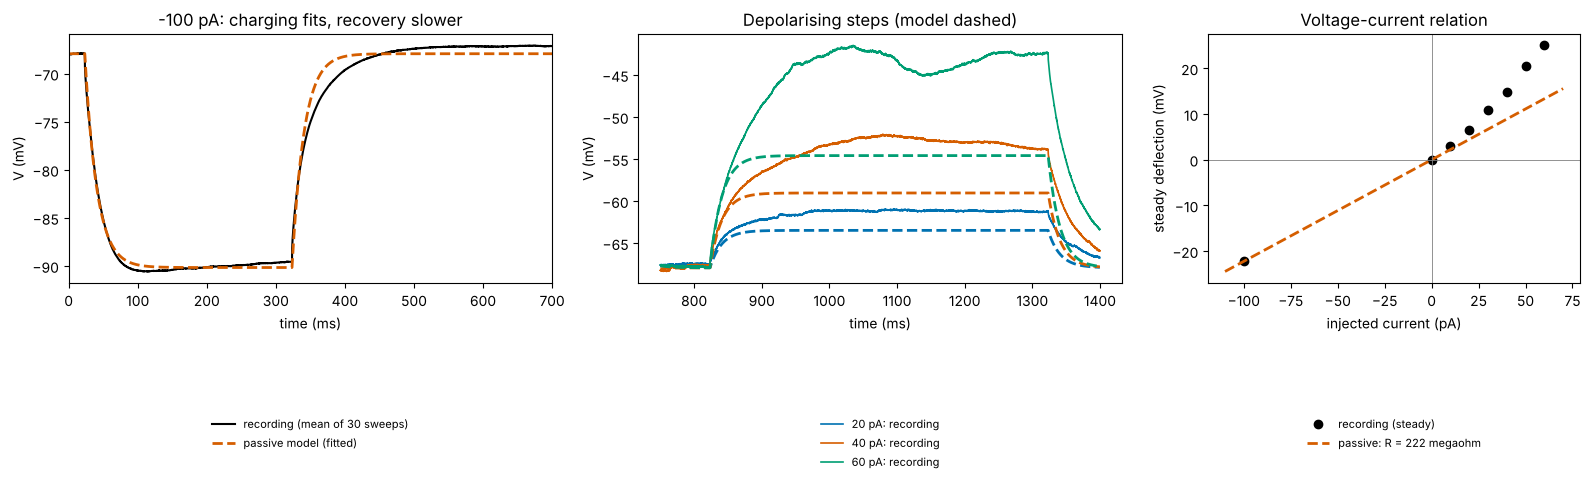

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6), gridspec_kw=dict(width_ratios=[1.3, 1.3, 1]))
ax = axes[0]
ax.plot(tt_ms, V_mean[seg], color='black', lw=1.5, label='recording (mean of 30 sweeps)')
ax.plot(tt_ms, V_ref, color=PALETTE[1], lw=2, ls='--', label='passive model (fitted)')
ax.set_xlim(0, 700); ax.set_xlabel('time (ms)'); ax.set_ylabel('V (mV)'); ax.set_title('-100 pA: charging fits, recovery slower')
ax.legend(fontsize=8, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.5), ncol=1)
ax = axes[1]
for k, s in enumerate([2, 4, 6]):
    t0 = int(0.75 * fs); seg2 = slice(t0, int(1.4 * fs)); tm2 = (t[seg2] - t[t0]) * 1e3
    I2 = I[s, seg2]
    v2 = euler(lambda v, tm: (-(v - E_L_hat) + R_mVpA * np.interp(tm, tm2, I2)) / tau_ms, V[s, pre_w].mean(), tm2)
    ax.plot(t[seg2] * 1e3, V[s, seg2], color=PALETTE[k], lw=1.2, label=f'{I_steps[s]:.0f} pA: recording')
    ax.plot(t[seg2] * 1e3, v2, color=PALETTE[k], lw=2, ls='--')
ax.set_xlabel('time (ms)'); ax.set_ylabel('V (mV)'); ax.set_title('Depolarising steps (model dashed)')
ax.legend(fontsize=8, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.5), ncol=1)
ax = axes[2]
sub = I_steps <= 60
ax.plot(np.r_[-100, I_steps[sub]], np.r_[V_inf_hat - E_L_hat, dV_obs[sub]], 'o', color='black', label='recording (steady)')
xs = np.linspace(-110, 70, 10)
ax.plot(xs, R_mVpA * xs, '--', color=PALETTE[1], lw=2, label=f'passive: R = {R_hat:.0f} megaohm')
ax.axhline(0, color='grey', lw=0.6); ax.axvline(0, color='grey', lw=0.6)
ax.set_xlabel('injected current (pA)'); ax.set_ylabel('steady deflection (mV)'); ax.set_title('Voltage-current relation')
ax.legend(fontsize=8, frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.5), ncol=1)
plt.tight_layout(); plt.show()

**Reading the mini-lab.**
- **Parameters.** The response to −100 pA is well described by a single exponential (RMSE about 0.4 mV, close to the recording noise): $\tau_m \approx 17$ ms, $R_m \approx 220$ MΩ, so $C_m = \tau_m/R_m \approx 80$ pF, all in the typical range of Part 3. Averaging 30 sweeps and bootstrapping over sweeps pins $\tau_m$ down to within about ±0.4 ms (17.1–17.8 ms) and $R_m$ to within about ±4 MΩ.
- **Numerics.** Euler with the recording's own sample interval (0.1 ms, under 1% of $\tau_m$) agrees with the reference solver to within about 0.02 mV, far below the recording noise. Here the numerical error is irrelevant; the **model error** is not.
- **Where the passive model fails.**
  1. *Recovery.* When the current switches off, the voltage jumps by about 1.3 mV within a sample and then recovers more slowly than it charged (a single-exponential fit gives about 34 ms against 17 ms). A passive single compartment has the same time constant on and off, and no jump. The jump is most likely an electrode artefact (uncompensated series resistance: $100\ \text{pA} \times$ about 13 MΩ); the slow tail is consistent with current spreading into dendrites, or with slow voltage-dependent channels such as $I_h$, which also produce the small sag (about 1 mV) visible during the step.
  2. *Depolarisation.* The fitted model predicts 2.2 mV per 10 pA. The neuron deflects 3.0 mV for 10 pA and 25 mV for 60 pA, 1.9 times the prediction: its effective resistance **grows** as it depolarises, because voltage-dependent channels (for example persistent sodium current) open near threshold. Linearity, and with it the passive model, holds only near rest and below it.
  3. *Spikes.* From 70 pA the neuron fires action potentials, which the membrane equation cannot produce at all.

The passive membrane is therefore a **local model**: valid for small deflections around rest, with parameters that are well determined but voltage-dependent. Lesson 22 keeps the passive equation below threshold and adds the missing piece by hand: a threshold, a spike and a reset.

**Limitations.** One neuron of undocumented type; parameters from the mean of 30 sweeps assume the cell did not change over the 10 minutes of recording; series-resistance and electrode artefacts were not corrected; the 10 kHz decimation is fine for subthreshold dynamics but blunts spike peaks.

# **Part 6: Applications in Neuroscience and Machine Learning**

| Idea | Neuroscience | Machine learning |
|---|---|---|
| First-order ODE, relaxation | membrane potential; calcium and neurotransmitter clearance; synaptic conductance decay; adaptation currents | continuous-time recurrent networks; neural ODEs; leaky units in spiking networks |
| Time constant | membrane integration window; synaptic and adaptation timescales; temporal summation | leak / decay rates; exponential moving averages (momentum, Adam's moment estimates, Lesson 15) |
| Equilibria and stability | resting potential; bistable persistent activity (working memory) | fixed points of recurrent networks and attractor models; convergence of training dynamics |
| Low-pass filtering | dendritic and membrane filtering of synaptic input; smoothing of spike trains | causal smoothing filters; leaky integration of evidence |
| Euler method, step size | simulators of neurons and networks (NEURON, Brian, NEST); choosing dt | the gradient-descent update is Euler's method on the gradient flow $d\theta/dt = -\nabla L$ (Lesson 12); residual networks as Euler steps |
| Model fitting and checking | passive parameters from current steps; detecting active conductances | fitting dynamical models to time series; checking residuals |

# **Part 7: Summary, Exit Ticket and Lesson 22 Preview**

| Idea | Formula / code | What to remember |
|---|---|---|
| First-order ODE | $dx/dt = f(x, t)$; autonomous if $f = f(x)$ | the derivative is the rate of change of the state |
| Initial-value problem | ODE + $x(t_0) = x_0$ | one solution per initial condition; curves do not cross |
| Equilibrium | $f(x^*) = 0$; stable if $f'(x^*) < 0$ | phase line: arrows towards stable points |
| Relaxation | $x(t) = x_\infty + (x_0 - x_\infty)e^{-t/\tau}$ | 63% after $\tau$, 95% after $3\tau$; half-life $\tau\ln 2$ |
| Membrane equation | $\tau_m dV/dt = -(V - E_L) + R_m I(t)$, $\tau_m = R_m C_m$ | steady level $E_L + R_m I$; linear; low-pass filter |
| Units | MΩ × pF = µs; MΩ × pA = µV | 200 MΩ, 100 pF → 20 ms; 100 pA → 20 mV |
| Euler | `x[n+1] = x[n] + dt * f(x[n], t[n])` | local error $O(\Delta t^2)$, global $O(\Delta t)$; unstable if $\Delta t > 2\tau$ |
| Reference solver | `solve_ivp(f, [t0, t1], [x0], rtol=...)` | adaptive, higher order; check numerics by halving dt |
| Model checking | fit near rest; test other inputs | real neurons: passive only near rest |

**Exit ticket.** A neuron has input resistance 150 MΩ and capacitance 120 pF. (a) What is its membrane time constant? (b) A 50 pA step is applied: what is the steady deflection, and how long until it is within 5% of it? (c) You simulate it with Euler and $\Delta t = 1$ ms. Is that safe?

*(Answers: (a) 150 MΩ × 120 pF = 18 ms. (b) 150 MΩ × 50 pA = 7.5 mV; 5% remains after $3\tau$ = 54 ms. (c) Stable ($\Delta t \ll 2\tau$), and the worst error is about 1% of the deflection (0.08 mV here); halve the step and check that nothing changes, or use 0.1 ms.)*

**Lesson 22 — Leaky integrate-and-fire neurons.** The passive membrane cannot fire. Lesson 22 adds an event rule to the same equation: when $V$ reaches a threshold, record a spike, reset $V$, and hold it for a refractory period. That gives rheobase, interspike intervals and F–I curves, and the mini-lab neuron's spiking sweeps become something to fit.

**Further reading.** P. Dayan and L. F. Abbott, *Theoretical Neuroscience* (2001), Chapter 5.1–5.4; W. Gerstner, W. M. Kistler, R. Naud and L. Paninski, *Neuronal Dynamics* (2014), Chapter 1 (free online); S. H. Strogatz, *Nonlinear Dynamics and Chaos* (2nd ed., 2015), Chapter 2; the Neuromatch Academy Computational Neuroscience tutorials on differential equations (W2D2), CC-BY.